# Lab 7 · Healthcare Operations and Resource Optimization

**AI in Healthcare · Completed simulation lab**

This notebook compares appointment booking and queue rules for a fictional two-clinician clinic, open 09:00–17:00. It uses 300 matched days per policy in each of three scenarios, for 3,600 policy-day runs. Run all cells in order with Python, NumPy, pandas, and Matplotlib. The fixture is generated in memory.

| Nominal scenario | Baseline FCFS | Reserve two | Overbook two | Urgent priority |
|---|---:|---:|---:|---:|
| Routine bookings | 30 | 28 | 32 | 30 |
| Median visits completed by closing | 30 | 28 | 31 | 30 |
| 90th percentile of daily p90 wait (min) | 54.7 | 47.2 | 60.2 | 59.1 |
| 90th-percentile overtime (min) | 19.8 | 7.9 | 35.7 | 21.3 |
| Urgent visits waiting over 30 min | 20.7% | 14.2% | 25.6% | 1.1% |

The 30-minute urgent-wait threshold belongs to this synthetic exercise. The earlier heart-disease notebook is separate from the scheduling fixture.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.style.use("seaborn-v0_8-whitegrid")
CLINIC_CLOSE_MINUTE = 480
BASE_TEMPLATE_SIZE = 30
N_CLINICIANS = 2
URGENT_WAIT_REVIEW_MIN = 30

def make_synthetic_requests(seed=7, n_requests=40):
    rng = np.random.default_rng(seed)
    access_group = rng.choice(
        ["near_clinic", "far_from_clinic"], size=n_requests, p=[0.65, 0.35]
    )
    travel_minutes = np.where(
        access_group == "near_clinic",
        rng.integers(5, 31, n_requests),
        rng.integers(35, 91, n_requests),
    )
    prior_missed = rng.binomial(2, np.where(access_group == "near_clinic", 0.12, 0.22))
    raw_score = -2.8 + 0.018 * travel_minutes + 0.75 * prior_missed
    return pd.DataFrame({
        "request_id": [f"R{i:03d}" for i in range(n_requests)],
        "patient_id": [f"P{i:03d}" for i in range(n_requests)],
        "request_order": np.arange(1, n_requests + 1),
        "access_group": access_group,
        "travel_minutes": travel_minutes,
        "prior_missed_appointments": prior_missed,
        "predicted_no_show_probability": np.clip(1 / (1 + np.exp(-raw_score)), 0.05, 0.60),
    })

requests = make_synthetic_requests()
display(requests.head())

,request_id,patient_id,request_order,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability
0,R000,P000,1,near_clinic,18,0,0.077558
1,R001,P001,2,far_from_clinic,68,1,0.304492
2,R002,P002,3,far_from_clinic,59,0,0.149567
3,R003,P003,4,near_clinic,27,0,0.089970
4,R004,P004,5,near_clinic,9,1,0.131473


## 1. Audit appointment requests

In [2]:
assert len(requests) == 40
assert requests.request_id.is_unique and requests.patient_id.is_unique
assert not requests.isna().any().any() and "showed_up" not in requests
assert requests.predicted_no_show_probability.between(0.05, 0.60).all()
assert requests.prior_missed_appointments.between(0, 2).all()
assert requests.loc[requests.access_group.eq("near_clinic"), "travel_minutes"].between(5, 30).all()
assert requests.loc[requests.access_group.eq("far_from_clinic"), "travel_minutes"].between(35, 90).all()
print(f"{len(requests)} rows, {requests.request_id.nunique()} unique requests, {requests.patient_id.nunique()} unique patients")
display(requests.agg(["min", "max"]).T.assign(missing=requests.isna().sum()))
request_audit_by_group = requests.groupby("access_group").agg(
    requests=("request_id", "size"),
    mean_predicted_no_show=("predicted_no_show_probability", "mean"),
    min_predicted_no_show=("predicted_no_show_probability", "min"),
    max_predicted_no_show=("predicted_no_show_probability", "max"),
)
display(request_audit_by_group.round(3))

40 rows, 40 unique requests, 40 unique patients


,min,max,missing
request_id,R000,R039,0
patient_id,P000,P039,0
request_order,1,40,0
access_group,far_from_clinic,near_clinic,0
travel_minutes,6,89,0
prior_missed_appointments,0,1,0
predicted_no_show_probability,0.063447,0.31995,0


,requests,mean_predicted_no_show,min_predicted_no_show,max_predicted_no_show
access_group,,,,
far_from_clinic,11,0.198,0.117,0.320
near_clinic,29,0.097,0.063,0.171


One row is one appointment request. All 40 requests have distinct request IDs and, in this fixture, distinct patient IDs. There are no missing values. Travel spans 6–89 minutes, prior misses span 0–1, and predicted non-attendance spans 0.063–0.320. The far group has 11 requests with a mean predicted probability of 0.198. The near group has 29 with a mean of 0.097.

The non-attendance score is a pre-opening prediction. The booking and slot are decisions, and `showed_up` is an outcome realized later. Putting realized attendance in the scheduler's input would leak future information. The score uses travel time and prior missed appointments, so its subgroup differences partly reflect how the fixture was constructed. Access group is separate from clinical urgency.

## Scheduling and queue engine

The template has two places every 30 minutes from 09:00 through 16:00. Reservations remove evenly spaced routine places. The score-guided policy puts extra requests into slots occupied by the two standard bookings with the highest predicted non-attendance. Urgent visits join at their simulated arrival time. A free clinician selects the earliest arrival under FCFS, or the earliest waiting urgent visit under priority.

**Reproducibility adjustment.** The lab's supplied simulation assigns routine random draws by row position and draws service and arrival noise only after selecting attendees. Reordering bookings or changing attendance can therefore change a shared patient's draws even with the same seed. Here the routine streams draw once per original request index before selecting attendees. The score, distribution parameters, policy rules and seeds are preserved. Individual seeded traces can differ from the supplied implementation.

In [3]:
def build_schedule(
    request_table, reserve_slots=0, overbook_slots=0, score_guided_overbooking=False
):
    """Assign appointments before opening, using request order and scores."""
    regular_places = BASE_TEMPLATE_SIZE - reserve_slots
    if not (0 <= reserve_slots < BASE_TEMPLATE_SIZE and 0 <= overbook_slots <= regular_places):
        raise ValueError("Invalid reservation or overbooking count")
    if regular_places + overbook_slots > len(request_table):
        raise ValueError("Insufficient requests")
    template = np.repeat(np.arange(0, 450, 30), 2)
    if reserve_slots:
        reserved_positions = np.floor(
            (np.arange(reserve_slots) + 0.5) * len(template) / reserve_slots
        ).astype(int)
        template = np.delete(template, reserved_positions)
    ordered = request_table.sort_values("request_order")
    selected = ordered.head(regular_places).copy()
    selected["scheduled_minute"] = template
    selected["booking_type"] = "standard"
    if overbook_slots:
        extra = ordered.iloc[regular_places:regular_places + overbook_slots].copy()
        if score_guided_overbooking:
            hosts = selected.nlargest(overbook_slots, "predicted_no_show_probability")
        else:
            hosts = selected.tail(overbook_slots)
        extra["scheduled_minute"] = hosts.scheduled_minute.to_numpy()
        extra["booking_type"] = "overbooked"
        selected = pd.concat([selected, extra], ignore_index=True)
    return selected.sort_values(
        ["scheduled_minute", "booking_type", "request_order"], kind="stable"
    ).reset_index(drop=True)

def process_queue(arrivals, n_clinicians=N_CLINICIANS, queue_rule="fcfs"):
    """Assign the next waiting visit when a clinician is free."""
    if queue_rule not in {"fcfs", "urgent_priority"} or n_clinicians < 1:
        raise ValueError("Invalid queue rule or clinician count")
    use_priority = queue_rule == "urgent_priority"
    pending = arrivals.sort_values(["arrival_minute", "visit_id"]).to_dict("records")
    waiting = []
    available = np.zeros(n_clinicians)
    records = []
    next_visit = 0
    now = 0.0
    while next_visit < len(pending) or waiting:
        if not waiting:
            now = max(now, pending[next_visit]["arrival_minute"])
        while next_visit < len(pending) and pending[next_visit]["arrival_minute"] <= now:
            waiting.append(pending[next_visit])
            next_visit += 1
        for server in np.flatnonzero(available <= now):
            if not waiting:
                break
            chosen = min(
                range(len(waiting)),
                key=lambda i: (
                    use_priority and waiting[i]["urgency"] != "urgent",
                    waiting[i]["arrival_minute"], waiting[i]["visit_id"],
                ),
            )
            visit = waiting.pop(chosen)
            finish = now + visit["service_duration_min"]
            records.append({
                **visit, "clinician": server + 1, "service_start_minute": now,
                "completion_minute": finish, "wait_min": now - visit["arrival_minute"],
            })
            available[server] = finish
        if waiting:
            now = float(available.min())
    columns = [*arrivals.columns, "clinician", "service_start_minute", "completion_minute", "wait_min"]
    return pd.DataFrame(records, columns=columns)

def simulate_clinic_day(
    schedule, seed, n_clinicians=N_CLINICIANS, queue_rule="fcfs",
    urgent_rate=4.0, no_show_logit_shift=0.0, request_pool_size=40,
):
    """Realize a day with random draws keyed to request order."""
    attendance_rng, arrival_rng, service_rng, count_rng, time_rng, duration_rng = [
        np.random.default_rng(stream) for stream in np.random.SeedSequence(seed).spawn(6)
    ]
    request_index = schedule.request_order.to_numpy() - 1
    assert ((request_index >= 0) & (request_index < request_pool_size)).all()
    scores = schedule.predicted_no_show_probability.to_numpy()
    actual_no_show = 1 / (1 + np.exp(-(np.log(scores / (1 - scores)) + no_show_logit_shift)))
    showed_up = attendance_rng.random(request_pool_size)[request_index] >= actual_no_show
    attended = schedule.loc[showed_up].copy()
    attended_index = request_index[showed_up]
    attended["visit_id"] = "V-" + attended.request_id
    attended["source"] = "scheduled"
    attended["urgency"] = "routine"
    attended["arrival_minute"] = np.maximum(
        0, attended.scheduled_minute + arrival_rng.normal(0, 8, request_pool_size)[attended_index]
    )
    attended["service_duration_min"] = np.clip(
        service_rng.lognormal(np.log(24), 0.35, request_pool_size)[attended_index], 8, 60
    )
    urgent_count = count_rng.poisson(urgent_rate)
    urgent = pd.DataFrame({
        "visit_id": [f"U-{seed}-{i}" for i in range(urgent_count)],
        "patient_id": [f"UP-{seed}-{i}" for i in range(urgent_count)],
        "access_group": "not_recorded_for_urgent_fixture",
        "booking_type": "same_day_request", "source": "same_day", "urgency": "urgent",
        "arrival_minute": time_rng.uniform(0, 420, urgent_count),
        "service_duration_min": np.clip(
            duration_rng.lognormal(np.log(30), 0.35, urgent_count), 10, 75
        ),
    })
    arrivals = pd.concat([attended, urgent], ignore_index=True, sort=False)
    return process_queue(arrivals, n_clinicians, queue_rule)

### Deterministic queue checks

In [4]:
toy_arrivals = pd.DataFrame({
    "visit_id": ["P1", "P2", "P3"], "urgency": ["routine"] * 3,
    "arrival_minute": [0.0, 5.0, 25.0], "service_duration_min": [20.0, 15.0, 10.0],
})
toy_result = process_queue(toy_arrivals, n_clinicians=1)
assert toy_result.wait_min.tolist() == [0, 15, 10]
assert toy_result.completion_minute.tolist() == [20, 35, 45]
priority_toy = toy_arrivals.assign(arrival_minute=[0, 5, 10], urgency=["routine", "routine", "urgent"])
priority_result = process_queue(priority_toy, n_clinicians=1, queue_rule="urgent_priority")
assert priority_result.visit_id.tolist() == ["P1", "P3", "P2"]
assert priority_result.service_start_minute.tolist() == [0, 20, 30]
print("FCFS and non-preemptive priority checks passed.")
display(toy_result)
display(priority_result)

FCFS and non-preemptive priority checks passed.


,visit_id,urgency,arrival_minute,service_duration_min,clinician,service_start_minute,completion_minute,wait_min
0,P1,routine,0.0,20.0,1,0.0,20.0,0.0
1,P2,routine,5.0,15.0,1,20.0,35.0,15.0
2,P3,routine,25.0,10.0,1,35.0,45.0,10.0


,visit_id,urgency,arrival_minute,service_duration_min,clinician,service_start_minute,completion_minute,wait_min
0,P1,routine,0,20.0,1,0.0,20.0,0.0
1,P3,urgent,10,10.0,1,20.0,30.0,10.0
2,P2,routine,5,15.0,1,30.0,45.0,25.0


Under FCFS, P1 occupies the clinician from minute 0 to 20. P2 arrived at 5 and starts at 20, waiting 15 minutes. P3 arrived at 25 and starts at 35, waiting 10 minutes. In the priority check P3 arrives at 10 as urgent, waits until P1 finishes, and is served before the already-waiting P2.

## 2. Trace a baseline clinic day

40 requests, 30 bookings
28 attended bookings + 4 urgent visits = 32 queue visits


,visit_id,source,clinician,arrival_minute,service_start_minute,completion_minute,wait_min
10,V-R011,scheduled,2,131.88,163.09,177.99,31.20
2,V-R002,scheduled,1,21.35,43.57,65.67,22.22
11,V-R010,scheduled,1,149.23,167.02,186.42,17.79
19,V-R018,scheduled,1,269.38,284.81,310.13,15.43
7,V-R007,scheduled,1,95.08,108.86,134.95,13.77


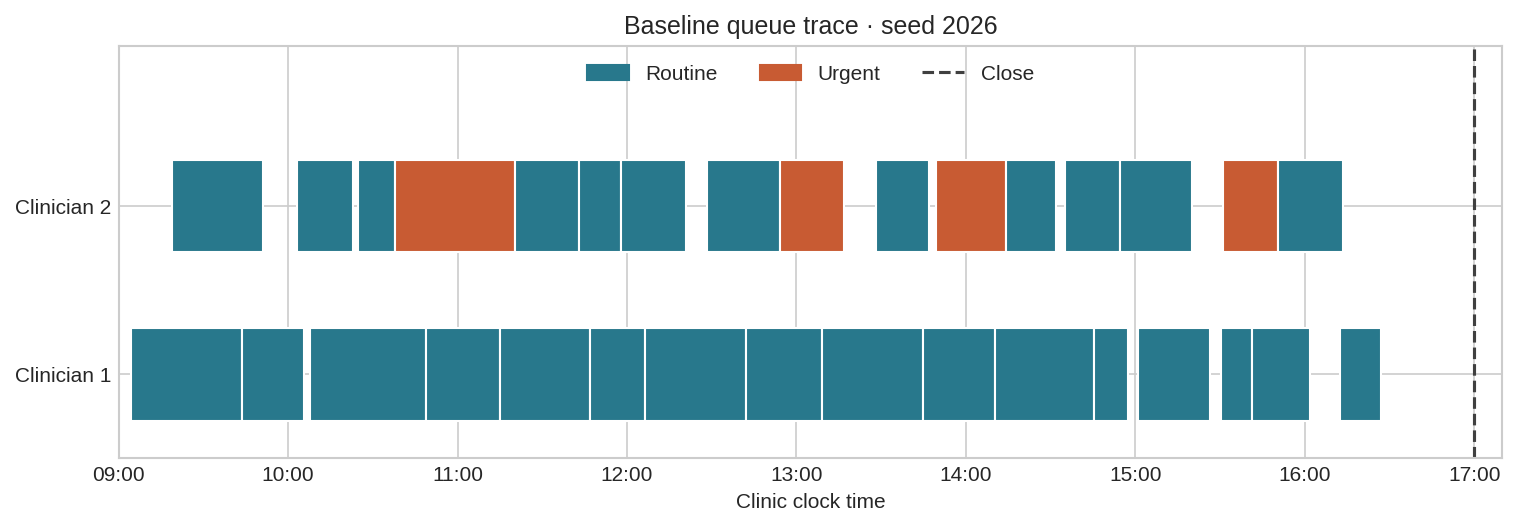

In [5]:
baseline_schedule = build_schedule(requests)
baseline_day = simulate_clinic_day(baseline_schedule, seed=2026)
assert baseline_day.visit_id.is_unique
assert baseline_day.wait_min.ge(0).all() and baseline_day.service_duration_min.gt(0).all()
for _, by_clinician in baseline_day.groupby("clinician"):
    assert (by_clinician.service_start_minute.to_numpy()[1:] >= by_clinician.completion_minute.to_numpy()[:-1]).all()
print(f"{len(requests)} requests, {len(baseline_schedule)} bookings")
print(f"{baseline_day.source.eq('scheduled').sum()} attended bookings + {baseline_day.source.eq('same_day').sum()} urgent visits = {len(baseline_day)} queue visits")
trace_columns = [
    "visit_id", "source", "clinician", "arrival_minute", "service_start_minute", "completion_minute", "wait_min"
]
display(baseline_day.nlargest(5, "wait_min")[trace_columns].round(2))

colors = {"routine": "#28788c", "urgent": "#c85b33"}
fig, ax = plt.subplots(figsize=(10, 3.4), layout="constrained")
for visit in baseline_day.itertuples(index=False):
    ax.barh(visit.clinician, visit.service_duration_min, left=visit.service_start_minute,
            height=0.55, color=colors[visit.urgency], edgecolor="white")
ax.axvline(CLINIC_CLOSE_MINUTE, color="0.25", linestyle="--", label="Close")
handles = [Patch(color=color, label=urgency.title()) for urgency, color in colors.items()]
ax.legend(handles=[*handles, *ax.get_legend_handles_labels()[0]], loc="upper center", ncol=3)
ax.set(title="Baseline queue trace · seed 2026", xlabel="Clinic clock time",
       yticks=[1, 2], yticklabels=["Clinician 1", "Clinician 2"],
       xticks=np.arange(0, 481, 60), xlim=(0, max(490, baseline_day.completion_minute.max() + 5)),
       ylim=(0.5, 2.95))
ax.xaxis.set_major_formatter(FuncFormatter(lambda minute, _: f"{9 + int(minute)//60:02d}:{int(minute)%60:02d}"))
plt.show()

The baseline has 40 incoming routine requests and books 30. The queue contains 28 attended bookings plus four same-day urgent visits, so `len(baseline_day)` is 32. It omits the 10 unbooked routine requests and two no-shows. The longest wait is 31.20 minutes for a scheduled visit. The trace checks that each clinician serves at most one visit at a time.

## 3. Calculate operational outcomes

A visit starts or completes by close if the respective time is at most minute 480. Its contribution to utilization is `max(0, min(finish, 480) − max(start, 0))`, divided after summation by 960 staffed clinician-minutes. Overtime is the clinic's closing-time overrun, measured from 17:00 to the last completion if that completion is later. An urgent breach is a wait strictly greater than 30 minutes.

In [6]:
def summarise_day(
    visits, n_clinicians=N_CLINICIANS, closing_minute=CLINIC_CLOSE_MINUTE,
    urgent_wait_review_min=URGENT_WAIT_REVIEW_MIN,
):
    start = visits.service_start_minute.to_numpy(dtype=float)
    finish = visits.completion_minute.to_numpy(dtype=float)
    waits = visits.wait_min.to_numpy(dtype=float)
    urgent = visits.urgency.eq("urgent").to_numpy()
    busy = np.clip(np.minimum(finish, closing_minute) - np.maximum(start, 0), 0, None)
    median, p90 = np.quantile(waits, [0.5, 0.9]) if len(waits) else (np.nan, np.nan)
    return {
        "visits": len(visits),
        "started_by_close": int((start <= closing_minute).sum()),
        "completed_by_close": int((finish <= closing_minute).sum()),
        "mean_wait_min": waits.mean() if len(waits) else np.nan,
        "median_wait_min": median,
        "p90_wait_min": p90,
        "max_wait_min": waits.max() if len(waits) else np.nan,
        "utilization_before_close": busy.sum() / (n_clinicians * closing_minute),
        "overtime_min": max(0.0, finish.max() - closing_minute) if len(finish) else 0.0,
        "urgent_visits": int(urgent.sum()),
        "urgent_wait_breaches": int((urgent & (waits > urgent_wait_review_min)).sum()),
        "routine_visits": int((~urgent).sum()),
        "routine_wait_total": waits[~urgent].sum(),
    }

baseline_metrics = summarise_day(baseline_day)
assert 0 <= baseline_metrics["utilization_before_close"] <= 1
assert baseline_metrics["mean_wait_min"] <= baseline_metrics["max_wait_min"]
assert baseline_metrics["urgent_wait_breaches"] <= baseline_metrics["urgent_visits"]
assert baseline_metrics["completed_by_close"] <= baseline_metrics["started_by_close"] <= baseline_metrics["visits"]
edge_visits = pd.DataFrame({
    "service_start_minute": [470., 480.], "completion_minute": [490., 500.],
    "wait_min": [30., 31.], "urgency": ["urgent", "urgent"],
})
edge = summarise_day(edge_visits)
assert edge["utilization_before_close"] == 10 / 960
assert edge["overtime_min"] == 20 and edge["urgent_wait_breaches"] == 1
assert edge["started_by_close"] == 2 and edge["completed_by_close"] == 0
display(pd.Series(baseline_metrics, name="Baseline · seed 2026").round(3))

visits                       32.000
started_by_close             32.000
completed_by_close           32.000
mean_wait_min                 5.891
median_wait_min               3.565
p90_wait_min                 15.261
max_wait_min                 31.203
utilization_before_close      0.821
overtime_min                  0.000
urgent_visits                 4.000
urgent_wait_breaches          0.000
routine_visits               28.000
routine_wait_total          172.696
Name: Baseline · seed 2026, dtype: float64

All 32 visits finished by closing on the traced day. Mean wait was 5.89 minutes, median wait 3.56 minutes, and p90 wait 15.26 minutes. In-hours utilization was 82.1%, overtime was zero, and none of the four urgent visits exceeded 30 minutes. This day illustrates the calculations. The repeated-day distributions show how far a single day can be from the tail.

## 4. Compare four policies over repeated days

In [7]:
policy_definitions = {
    "baseline_fcfs": {"schedule": baseline_schedule, "queue_rule": "fcfs"},
    "reserve_2_fcfs": {"schedule": build_schedule(requests, reserve_slots=2), "queue_rule": "fcfs"},
    "overbook_2_score_guided": {
        "schedule": build_schedule(requests, overbook_slots=2, score_guided_overbooking=True),
        "queue_rule": "fcfs",
    },
    "baseline_urgent_priority": {"schedule": baseline_schedule, "queue_rule": "urgent_priority"},
}
policy_labels = {
    "baseline_fcfs": "Baseline FCFS", "reserve_2_fcfs": "Reserve two",
    "overbook_2_score_guided": "Overbook two", "baseline_urgent_priority": "Urgent priority",
}
schedule_summary = []
for name, policy in policy_definitions.items():
    schedule = policy["schedule"]
    slot_counts = schedule.scheduled_minute.value_counts()
    schedule_summary.append({
        "Policy": policy_labels[name], "Scheduled": len(schedule),
        "Overbooked": schedule.booking_type.eq("overbooked").sum(),
        "Unbooked": len(requests) - len(schedule), "Times with ≥2": slot_counts.ge(2).sum(),
        "Times with >2": slot_counts.gt(2).sum(), "Peak simultaneous bookings": slot_counts.max(),
        "Queue rule": policy["queue_rule"],
    })
display(pd.DataFrame(schedule_summary))
print("Times with more than two bookings under score-guided overbooking")
overbook_times = policy_definitions["overbook_2_score_guided"]["schedule"].scheduled_minute.value_counts()
display(overbook_times[overbook_times.gt(2)].sort_index().rename("Bookings").to_frame())

,Policy,Scheduled,Overbooked,Unbooked,Times with ≥2,Times with >2,Peak simultaneous bookings,Queue rule
0,Baseline FCFS,30,0,10,15,0,2,fcfs
1,Reserve two,28,0,12,13,0,2,fcfs
2,Overbook two,32,2,8,15,2,3,fcfs
3,Urgent priority,30,0,10,15,0,2,urgent_priority


Times with more than two bookings under score-guided overbooking


,Bookings
scheduled_minute,
60,3
390,3


Two appointments at a time are normal for this two-clinician template. Overbooking creates three bookings at 10:00 and 15:30. The `Unbooked` column measures routine requests that did not get a slot before opening. The repeated-day access measures below count service starts and completions for both scheduled and urgent arrivals.

In [8]:
simulation_seeds = np.arange(20_000, 20_300)

def evaluate_policies(seeds, urgent_rate=4.0, no_show_logit_shift=0.0, collect_groups=False):
    daily_rows, subgroup_frames = [], []
    for name, policy in policy_definitions.items():
        for seed in seeds:
            visits = simulate_clinic_day(
                policy["schedule"], seed=int(seed), queue_rule=policy["queue_rule"],
                urgent_rate=urgent_rate, no_show_logit_shift=no_show_logit_shift,
                request_pool_size=len(requests),
            )
            daily_rows.append({"policy": name, "seed": int(seed), **summarise_day(visits)})
            if collect_groups and name in {"baseline_fcfs", "overbook_2_score_guided"}:
                scheduled = visits.loc[visits.source.eq("scheduled"), ["request_id", "access_group", "wait_min"]]
                subgroup_frames.append(scheduled.assign(policy=name, seed=int(seed)))
    return pd.DataFrame(daily_rows), subgroup_frames

def summarize_policies(results):
    group = results.groupby("policy", sort=False)
    table = group.agg(
        median_visits=("visits", "median"),
        median_started=("started_by_close", "median"),
        median_completed=("completed_by_close", "median"),
        median_daily_mean_wait=("mean_wait_min", "median"),
        median_daily_p90_wait=("p90_wait_min", "median"),
        p90_daily_p90_wait=("p90_wait_min", lambda s: s.quantile(0.90)),
        median_utilization=("utilization_before_close", "median"),
        p90_overtime=("overtime_min", lambda s: s.quantile(0.90)),
        urgent_visits=("urgent_visits", "sum"),
        mean_urgent_breaches=("urgent_wait_breaches", "mean"),
    )
    sums = group[["routine_wait_total", "routine_visits", "urgent_wait_breaches", "urgent_visits"]].sum()
    table["mean_routine_wait"] = sums.routine_wait_total / sums.routine_visits
    table["urgent_breach_rate"] = sums.urgent_wait_breaches / sums.urgent_visits
    return table

policy_results, scheduled_frames = evaluate_policies(simulation_seeds, collect_groups=True)
policy_summary = summarize_policies(policy_results)
assert policy_results.groupby("policy").seed.nunique().eq(300).all()
assert policy_results.pivot(index="seed", columns="policy", values="urgent_visits").nunique(axis=1).eq(1).all()
display(policy_summary.rename(index=policy_labels).round(3))

,median_visits,median_started,median_completed,median_daily_mean_wait,median_daily_p90_wait,p90_daily_p90_wait,median_utilization,p90_overtime,urgent_visits,mean_urgent_breaches,mean_routine_wait,urgent_breach_rate
policy,,,,,,,,,,,,
Baseline FCFS,30.0,30.0,30.0,9.369,25.251,54.732,0.819,19.760,1173,0.810,13.049,0.207
Reserve two,28.0,28.0,28.0,7.540,20.623,47.226,0.771,7.858,1173,0.557,10.098,0.142
Overbook two,32.0,32.0,31.0,12.421,30.131,60.184,0.866,35.654,1173,1.000,16.214,0.256
Urgent priority,30.0,30.0,30.0,9.607,26.450,59.074,0.819,21.331,1173,0.043,14.750,0.011


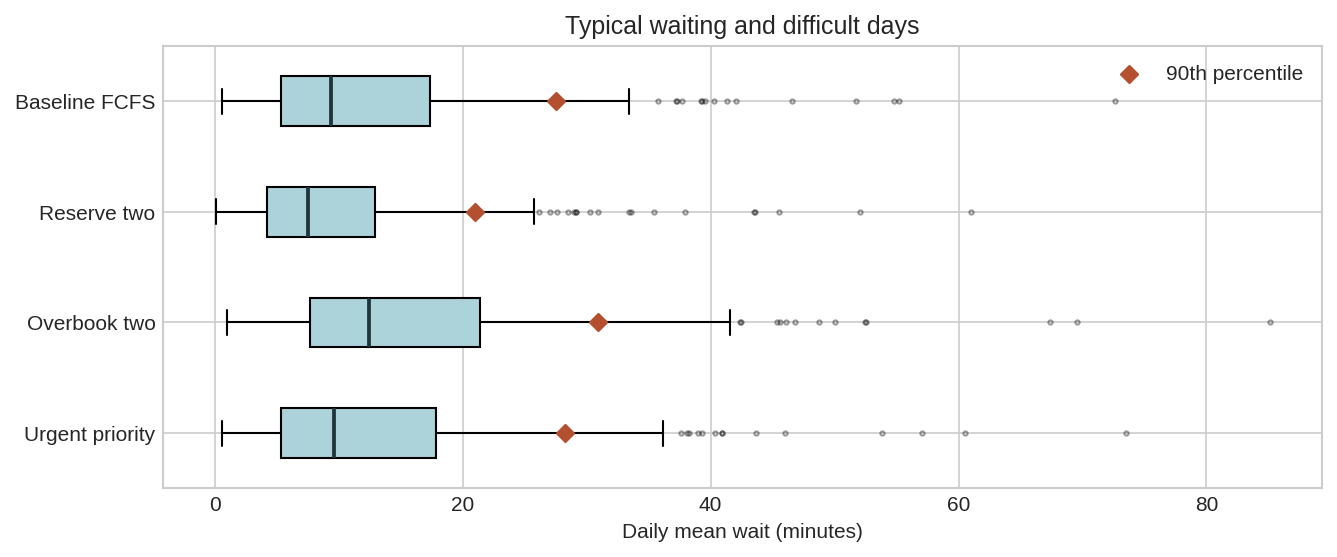

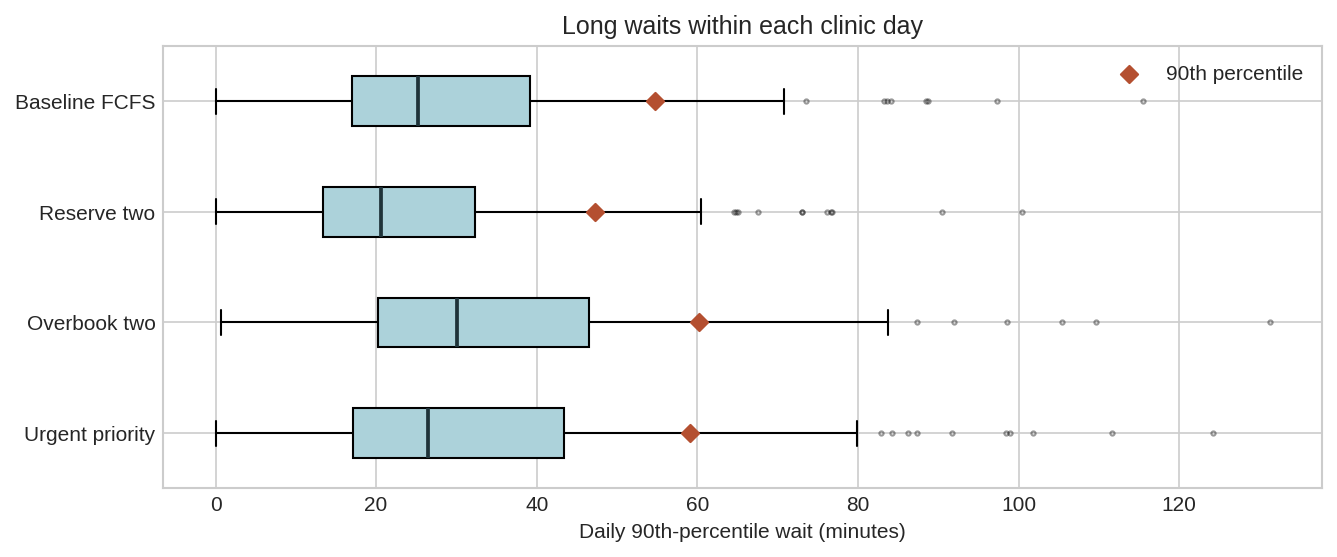

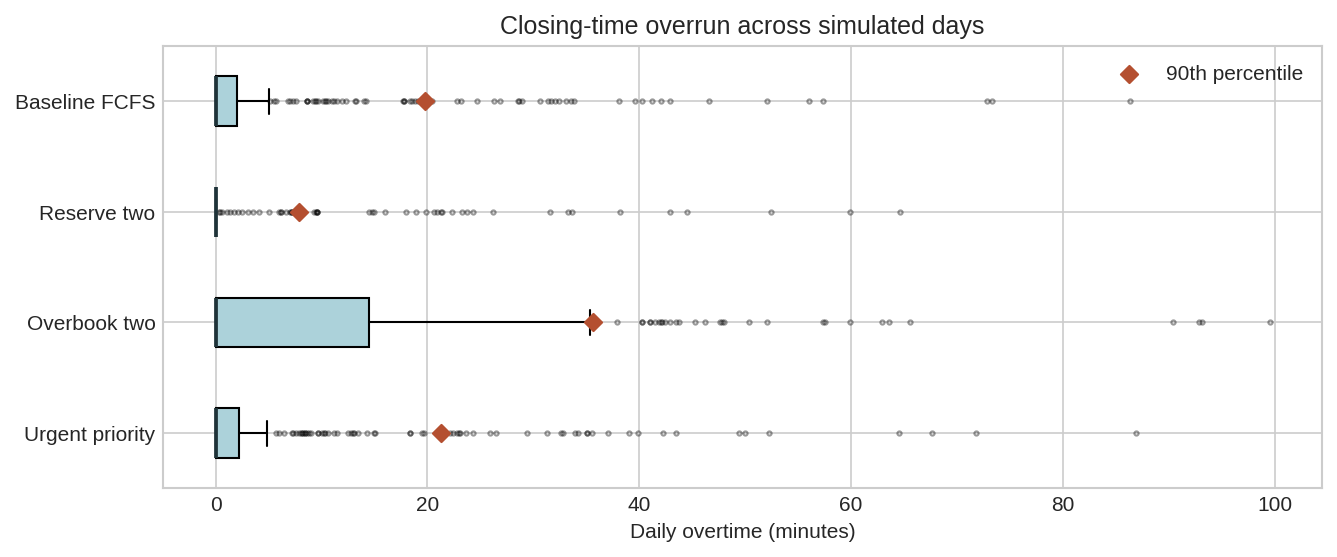

In [9]:
def plot_policy_distribution(metric, title, x_label):
    values = [policy_results.loc[policy_results.policy.eq(name), metric] for name in policy_labels]
    fig, ax = plt.subplots(figsize=(8.8, 3.6), layout="constrained")
    boxes = ax.boxplot(values, vert=False, tick_labels=list(policy_labels.values()), patch_artist=True,
                       medianprops={"color": "#1f3339", "linewidth": 1.8},
                       flierprops={"marker": ".", "markersize": 4, "alpha": 0.4})
    for box in boxes["boxes"]:
        box.set_facecolor("#acd2da")
    p90 = [sample.quantile(0.90) for sample in values]
    ax.scatter(p90, np.arange(1, len(values) + 1), color="#b44f30", marker="D", s=34, zorder=3, label="90th percentile")
    ax.invert_yaxis()
    ax.set(title=title, xlabel=x_label)
    ax.legend(loc="upper right")
    plt.show()

plot_policy_distribution("mean_wait_min", "Typical waiting and difficult days", "Daily mean wait (minutes)")
plot_policy_distribution("p90_wait_min", "Long waits within each clinic day", "Daily 90th-percentile wait (minutes)")
plot_policy_distribution("overtime_min", "Closing-time overrun across simulated days", "Daily overtime (minutes)")

1. **Access.** Score-guided overbooking has the most starts and completions by close, with medians of 32 and 31 respectively. The baseline and urgent priority both have medians of 30 for each.
2. **Tail waits and overtime.** Reserve two has the lowest 90th percentile of daily p90 waits (47.2 minutes) and the lowest p90 overtime (7.9 minutes), while booking only 28 routine requests.
3. **Urgency.** Urgent priority reduces breaches from 0.810 to 0.043 per day (20.7% to 1.1% of urgent visits). The pooled routine mean wait increases from 13.05 to 14.75 minutes because urgent patients can move ahead in the queue.
4. **Trade-offs.** No policy dominates. Overbooking increases access at the cost of delays, reservation reduces workload at the cost of two routine places, and priority improves urgent waits while shifting some delay to routine visits.
5. **Constraints.** Treat urgent-wait breaches, staffing limits on overtime, and unacceptable subgroup waits as explicit review constraints. Set allowable rates and actions in advance. Additional throughput should be compared among policies that meet those constraints.

A single mean across simulations can hide days with long waits or substantial overtime. The median describes a typical day, while the upper percentiles show what happens on more difficult days. The 90th percentile of daily p90 wait first computes a patient-wait percentile within each day and then a percentile across days.

### Paired uncertainty check

Bootstrap the 300 matched seed differences. These intervals describe Monte Carlo uncertainty for mean contrasts under the specified simulator. They leave uncertainty about the real clinic and the assumed data-generating process unresolved.

In [10]:
rng = np.random.default_rng(2026)
bootstrap_indices = rng.integers(0, len(simulation_seeds), size=(4000, len(simulation_seeds)))
contrast_rows = []
for metric in ["started_by_close", "p90_wait_min", "overtime_min", "urgent_wait_breaches"]:
    daily = policy_results.pivot(index="seed", columns="policy", values=metric)
    for name in list(policy_labels)[1:]:
        paired_change = (daily[name] - daily["baseline_fcfs"]).to_numpy()
        means = paired_change[bootstrap_indices].mean(axis=1)
        lower, upper = np.quantile(means, [0.025, 0.975])
        contrast_rows.append({
            "Policy": policy_labels[name], "Daily measure": metric,
            "Paired days": len(paired_change), "Mean change": paired_change.mean(),
            "95% MC lower": lower, "95% MC upper": upper,
        })
display(pd.DataFrame(contrast_rows).round(3))

,Policy,Daily measure,Paired days,Mean change,95% MC lower,95% MC upper
0,Reserve two,started_by_close,300,-1.777,-1.830,-1.723
1,Overbook two,started_by_close,300,1.657,1.587,1.723
2,Urgent priority,started_by_close,300,-0.023,-0.053,0.003
3,Reserve two,p90_wait_min,300,-4.767,-5.520,-4.023
4,Overbook two,p90_wait_min,300,5.115,4.467,5.762
5,Urgent priority,p90_wait_min,300,2.350,1.829,2.902
6,Reserve two,overtime_min,300,-2.565,-3.416,-1.737
7,Overbook two,overtime_min,300,4.584,3.774,5.483
8,Urgent priority,overtime_min,300,-0.091,-0.340,0.144
9,Reserve two,urgent_wait_breaches,300,-0.253,-0.340,-0.173


## 5. Stress-test demand and attendance

In [11]:
surge_results, _ = evaluate_policies(simulation_seeds, urgent_rate=7.0)
surge_summary = summarize_policies(surge_results)
attendance_drift_results, _ = evaluate_policies(simulation_seeds, no_show_logit_shift=-0.6)
attendance_drift_summary = summarize_policies(attendance_drift_results)
print("Demand surge · mean of seven urgent arrivals per day")
display(surge_summary.rename(index=policy_labels).round(3))
print("Attendance drift · actual no-show odds multiplied by exp(-0.6) ≈ 0.55")
display(attendance_drift_summary.rename(index=policy_labels).round(3))

Demand surge · mean of seven urgent arrivals per day


,median_visits,median_started,median_completed,median_daily_mean_wait,median_daily_p90_wait,p90_daily_p90_wait,median_utilization,p90_overtime,urgent_visits,mean_urgent_breaches,mean_routine_wait,urgent_breach_rate
policy,,,,,,,,,,,,
Baseline FCFS,33.0,32.0,31.0,20.004,42.576,89.145,0.900,67.769,2042,2.680,25.027,0.394
Reserve two,31.0,31.0,30.0,14.774,35.757,76.112,0.862,44.476,2042,2.140,19.746,0.314
Overbook two,35.0,34.0,32.0,24.857,50.283,99.638,0.934,85.820,2042,3.183,30.155,0.468
Urgent priority,33.0,32.0,31.0,20.119,49.412,108.254,0.900,65.298,2042,0.233,31.301,0.034


Attendance drift · actual no-show odds multiplied by exp(-0.6) ≈ 0.55


,median_visits,median_started,median_completed,median_daily_mean_wait,median_daily_p90_wait,p90_daily_p90_wait,median_utilization,p90_overtime,urgent_visits,mean_urgent_breaches,mean_routine_wait,urgent_breach_rate
policy,,,,,,,,,,,,
Baseline FCFS,32.0,32.0,31.0,11.135,27.342,60.709,0.859,29.835,1173,0.933,15.105,0.239
Reserve two,30.0,30.0,29.0,8.457,23.249,50.681,0.805,14.795,1173,0.660,11.390,0.169
Overbook two,34.0,33.0,32.0,15.281,33.981,68.437,0.903,48.085,1173,1.233,19.289,0.315
Urgent priority,32.0,32.0,31.0,11.341,29.416,68.665,0.859,30.619,1173,0.040,17.065,0.010


- **Demand surge.** With mean urgent arrivals increasing from four to seven, overbooking still leads starts, but its p90 overtime rises from 35.7 to 85.8 minutes and urgent breaches rise from 25.6% to 46.8%. Priority keeps the urgent breach rate to 3.4%, while its p90 of daily p90 wait rises to 108.3 minutes. Reserve two still has the lowest p90 overtime, at 44.5 minutes.
- **Attendance drift.** A −0.6 logit shift makes patients more likely to attend without changing the scores or schedules. Overbooking retains some access advantage, but its p90 overtime rises to 48.1 minutes and urgent breaches reach 31.5%. With urgent priority, urgent breaches remain about 1%, while p90 overtime rises to 30.6 minutes.
- **Interpretation.** These are scenario tests of synthetic assumptions. They expose sensitivity to overload and score miscalibration. External validation would require independent clinic data and evaluation of patient and workflow outcomes in the intended setting.

## 6. Audit subgroup effects

In [12]:
comparison_names = ["baseline_fcfs", "overbook_2_score_guided"]
group_schedules = pd.concat([
    policy_definitions[name]["schedule"].assign(policy=name) for name in comparison_names
])
booking_audit_by_group = group_schedules.groupby(["policy", "access_group", "booking_type"]).size().unstack(fill_value=0)
booking_audit_by_group["booked_total"] = booking_audit_by_group.sum(axis=1)
booking_audit_by_group["request_pool"] = booking_audit_by_group.index.get_level_values("access_group").map(requests.access_group.value_counts())
booking_audit_by_group["unbooked"] = booking_audit_by_group.request_pool - booking_audit_by_group.booked_total
display(booking_audit_by_group.rename(index=policy_labels, level="policy"))

hosts = baseline_schedule.nlargest(2, "predicted_no_show_probability")
print("Standard patients whose slots host the extra bookings")
display(hosts[["request_id", "access_group", "scheduled_minute", "predicted_no_show_probability"]].round(3))

scheduled_visits = pd.concat(scheduled_frames, ignore_index=True)
subgroup_results = scheduled_visits.groupby(["policy", "access_group"]).agg(
    attended_n=("wait_min", "size"), unique_requests=("request_id", "nunique"),
    mean_wait_min=("wait_min", "mean"), p90_wait_min=("wait_min", lambda s: s.quantile(0.90)),
)
display(subgroup_results.rename(index=policy_labels, level="policy").round(3))

paired_visits = scheduled_visits.pivot(index=["seed", "request_id", "access_group"], columns="policy", values="wait_min").dropna()
paired_visits["extra_wait"] = paired_visits["overbook_2_score_guided"] - paired_visits["baseline_fcfs"]
matched_group_wait = paired_visits.groupby(level="access_group").extra_wait.agg(
    matched_n="size", mean_extra_wait="mean", p90_extra_wait=lambda s: s.quantile(0.90),
)
print("Matched scheduled visits under both policies")
display(matched_group_wait.round(3))

booking_type                   overbooked  standard  booked_total  request_pool  unbooked
policy        access_group                                                               
Baseline FCFS far_from_clinic           0         9             9            11         2
              near_clinic               0        21            21            29         8
Overbook two  far_from_clinic           0         9             9            11         2
              near_clinic               2        21            23            29         6

Standard patients whose slots host the extra bookings


,request_id,access_group,scheduled_minute,predicted_no_show_probability
5,R005,far_from_clinic,60,0.32
27,R027,far_from_clinic,390,0.32


attended_n  unique_requests  mean_wait_min  p90_wait_min
policy        access_group                                                             
Baseline FCFS far_from_clinic        2149                9         11.146        34.752
              near_clinic            5710               21         13.766        39.655
Overbook two  far_from_clinic        2149                9         14.137        40.400
              near_clinic            6253               23         16.927        45.494

Matched scheduled visits under both policies


,matched_n,mean_extra_wait,p90_extra_wait
access_group,,,
far_from_clinic,2149,2.991,12.208
near_clinic,5710,3.274,12.535


Both extra bookings went to near-clinic requests, while both high-score standard bookings that hosted them belonged to far-clinic patients. The policy books 23 of 29 near requests and 9 of 11 far requests, compared with 21 of 29 and 9 of 11 at baseline.

For the far group, mean wait rose from 11.15 to 14.14 minutes across 2,149 attended visits under each policy. For the near group it rose from 13.77 minutes (5,710 visits) to 16.93 (6,253 visits). Those counts repeat a small fixed set of fictional request IDs over 300 days. Among matched request-day visits, average increases are 2.99 minutes for the far group (2,149) and 3.27 for the near group (5,710). The host pattern shows how a score linked to travel can concentrate overlapping bookings, but these observed differences depend on the synthetic roster, attendance and slot choices. They justify further investigation and do not establish discrimination or patient harm. Same-day urgent visits are excluded because the fixture supplies no access group for them.

## 7. Recommendation memo

**To the clinic manager**

I recommend evaluating non-preemptive urgent priority in a limited, staff-supervised pilot after checking the policy against local workflow data. It keeps 30 routine bookings and a median of 30 completions by closing. In the nominal simulations, urgent breaches fell from 20.7% with baseline FCFS to 1.1%. The 90th percentile of daily p90 waits increased from 54.7 to 59.1 minutes, and p90 overtime increased from 19.8 to 21.3 minutes.

Under the demand surge, priority held urgent breaches to 3.4%, but p90 overtime reached 65.3 minutes. With higher attendance, urgent breaches stayed around 1% and p90 overtime rose to 30.6 minutes. I would defer score-guided overbooking. Both overlapping slots were hosted by far-clinic patients, and their mean wait rose by 3.0 minutes across 2,149 matched attended visits.

The charge clinician should be able to override queue order based on reassessment and trigger the clinic’s established escalation pathway when an urgent delay is expected. Track urgent breaches, routine p90 waits by access group, and p90 overtime. Agree on review and pause criteria before the pilot. The simulator reuses a fixed synthetic request pool with uninterrupted staffing, so it cannot estimate the effects of local case mix, breaks, or staffing disruptions.

## Reflection questions

1. **Why do patients wait below nominal capacity?** The daily total hides peaks. Arrivals can cluster and variable consultations can occupy both clinicians when the next patients arrive, even if the same clinicians are idle later.
2. **What was known at scheduling time?** Request order, the clinic template, and the predicted no-show scores were known. Travel time, missed-appointment history, and access group were fixture attributes. Attendance, arrival deviations, durations, and urgent demand were realized later.
3. **Why can maximizing utilization go wrong?** Keeping clinicians continuously busy removes slack. A delay or urgent arrival can then create a long queue and overtime, even if higher utilization appears efficient on paper.
4. **What is non-preemptive priority?** It selects a waiting urgent visit at the next service opportunity. A clinician finishes the visit already in progress before starting another.
5. **What is missing?** The fixture omits rooms, breaks, staff roles and skills, triage and reassessment, and patients who leave or rebook. Uninterrupted clinician availability is particularly important because breaks and absences reduce effective capacity and can concentrate waits around busy periods.
6. **How might deployment change retraining data?** A policy changes who receives an appointment and the time offered. Unbooked requests generate no attendance label, and waits, reminders, or rescheduling can alter attendance among those booked. Log policy versions, offers, bookings, overrides, and follow-up outcomes so future data can distinguish changing behavior from changing selection.
7. **What evidence would a real clinic need?** Use local timestamped records to verify the arrival, attendance, service and staffing assumptions, assess score calibration and subgroup effects, and compare predicted with observed outcomes in a silent trial. A supervised evaluation should measure access, urgent delays, overtime, and patient impacts with predefined escalation and pause criteria.

In [13]:
baseline_2026 = simulate_clinic_day(baseline_schedule, seed=2026)
overbook_2026 = simulate_clinic_day(policy_definitions["overbook_2_score_guided"]["schedule"], seed=2026)
event_fields = ["arrival_minute", "service_duration_min"]
base_events = baseline_2026.set_index("visit_id")[event_fields].sort_index()
overbook_events = overbook_2026.set_index("visit_id")[event_fields].sort_index()
assert base_events.index.isin(overbook_events.index).all()
pd.testing.assert_frame_equal(base_events, overbook_events.loc[base_events.index])
for scenario in [policy_results, surge_results, attendance_drift_results]:
    assert len(scenario) == 1200 and not scenario.duplicated(["policy", "seed"]).any()
    assert scenario.utilization_before_close.between(0, 1 + 1e-12).all()
    assert scenario.urgent_wait_breaches.le(scenario.urgent_visits).all()
    assert scenario.completed_by_close.le(scenario.started_by_close).all()
    assert scenario.started_by_close.le(scenario.visits).all()
assert subgroup_results.attended_n.sum() == len(scheduled_visits)
print("All lab checks passed.")

All lab checks passed.
